# Surface reconstruction from a point cloud

`reconstruct_surface(cloud)` turns an oriented point cloud (a scan read from PLY, PCD or XYZ) into a triangle surface: the zero level set of the signed distance to the samples' tangent planes (Hoppe et al. 1992), evaluated on a band of lattice cells about the samples and cut by marching tetrahedra. Missing normals are estimated first; an open scan stays open. See `doc/reconstruct_surface.md`.

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt

import meshioplusplus as mp

try:
    import pyvista as pv
    pv.OFF_SCREEN = True
except ImportError:  # pragma: no cover
    pv = None


def to_pyvista(mesh):
    """meshio++ Mesh -> pyvista grid via a temporary .vtu."""
    with tempfile.NamedTemporaryFile(suffix='.vtu', delete=False) as f:
        tmp = f.name
    try:
        mp.write(tmp, mesh)
        return pv.read(tmp)
    finally:
        os.unlink(tmp)


def render(panels, title, size=(1500, 560)):
    """Side-by-side PyVista renders embedded through matplotlib; a matplotlib
    trisurf fallback when GL is unavailable. Each panel is (mesh, subtitle,
    cloud or None)."""
    try:
        if pv is None:
            raise RuntimeError('no pyvista')
        pl = pv.Plotter(off_screen=True, shape=(1, len(panels)), window_size=size)
        for i, (mesh, sub, cloud) in enumerate(panels):
            pl.subplot(0, i)
            if mesh is not None and len(mesh.cells):
                pl.add_mesh(to_pyvista(mesh), color='#2ec4b6', show_edges=True,
                            edge_color='#1f4e79', line_width=0.3, smooth_shading=False)
            if cloud is not None:
                pl.add_points(np.asarray(cloud), color='#e76f51', point_size=3,
                              render_points_as_spheres=True)
            pl.add_text(sub, font_size=10)
            pl.camera_position = 'iso'
        pl.link_views()
        img = pl.screenshot(return_img=True)
        pl.close()
        plt.figure(figsize=(15, 5.6))
        plt.imshow(img)
        plt.axis('off')
        plt.title(title)
        plt.tight_layout()
        plt.show()
    except Exception as exc:  # head-less GL fallback
        print('PyVista render skipped:', exc)
        fig = plt.figure(figsize=(15, 5.6))
        for i, (mesh, sub, cloud) in enumerate(panels):
            ax = fig.add_subplot(1, len(panels), i + 1, projection='3d')
            if mesh is not None and len(mesh.cells):
                ax.plot_trisurf(*mesh.points.T, triangles=mesh.cells[0].data,
                                color='#2ec4b6', edgecolor='#1f4e79', linewidth=0.1)
            if cloud is not None:
                ax.scatter(*np.asarray(cloud).T, s=1, c='#e76f51')
            ax.set_title(sub); ax.set_axis_off(); ax.set_box_aspect((1, 1, 1))
        fig.suptitle(title)
        plt.tight_layout()
        plt.show()

## A lumpy closed scan

A body sampled with a little noise, with no normals: they are estimated first (`estimate_normals`, consistent orientation), then the tangent planes of the 8 nearest samples are blended at every lattice node. The result is one closed piece, wound outward.

{'num_samples': 8000, 'spacing': 0.0469, 'cell_size': 0.0469, 'max_distance': 0.0938, 'num_lattice_points': 58078, 'num_undefined': 5, 'num_triangles': 62796, 'num_components': 1, 'estimated_normals': True}


open edges: 0, enclosed volume 5.147 (positive: outward)


2026-11-02 16:42:15.925 (   0.819s) [    7FCF86CFD080]vtkXOpenGLRenderWindow.:1452  WARN| bad X server connection. DISPLAY=


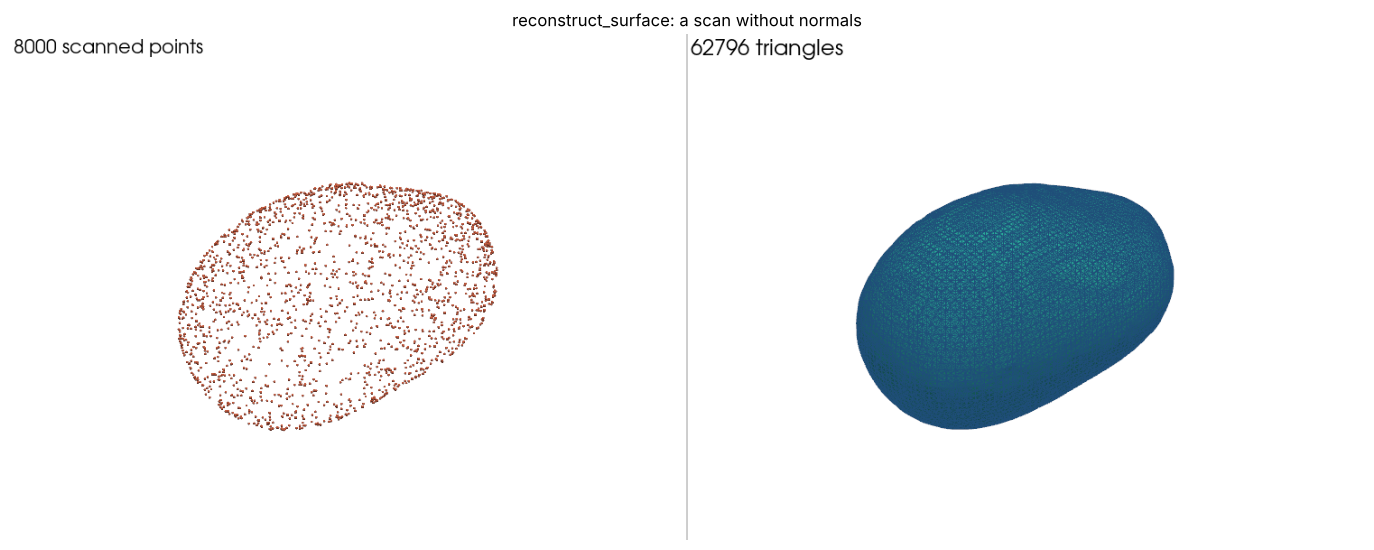

In [2]:
rng = np.random.default_rng(3)
d = rng.normal(size=(8000, 3))
d /= np.linalg.norm(d, axis=1)[:, None]
radius = 1.0 + 0.2 * np.sin(3 * d[:, 0]) * np.cos(2 * d[:, 1])
cloud = d * radius[:, None] * [1.5, 1.0, 0.8] + rng.normal(scale=0.003, size=(8000, 3))

surface, report = mp.reconstruct_surface(cloud, return_report=True)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in report.items()})

tri = surface.cells[0].data
edges = np.sort(np.concatenate([tri[:, [0, 1]], tri[:, [1, 2]], tri[:, [2, 0]]]), 1)
_, counts = np.unique(edges, axis=0, return_counts=True)
p = surface.points[tri]
volume = np.einsum('ij,ij->i', p[:, 0], np.cross(p[:, 1], p[:, 2])).sum() / 6
print(f'open edges: {(counts == 1).sum()}, enclosed volume {volume:.3f} (positive: outward)')

render([(None, f'{len(cloud)} scanned points', cloud[::4]),
        (surface, f'{report["num_triangles"]} triangles', None)],
       'reconstruct_surface: a scan without normals')

## How close: the sphere probe

Points on a unit sphere with exact normals. The Hausdorff distance to a finely tessellated sphere is a fraction of the sample spacing, for Hoppe's own field (`k=1`) and for the blended one; a coarser lattice (`resolution`) gives fewer triangles at a larger error.

k=1 (Hoppe)           33520 triangles  Hausdorff 0.00108  = 0.019 spacing
k=8 (default)         33608 triangles  Hausdorff 0.00163  = 0.028 spacing
k=8, resolution 16     7104 triangles  Hausdorff 0.00373  = 0.064 spacing


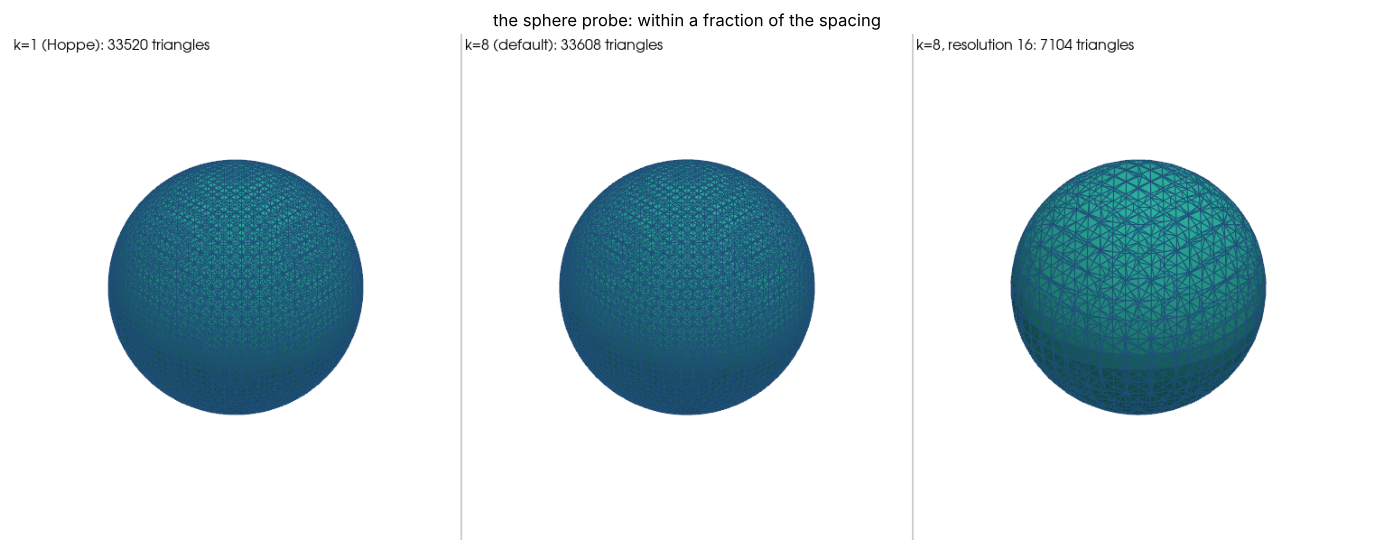

In [3]:
pts = mp.sphere_points(4000).points
reference = mp.icosa_sphere(1.0, 5)
rows = []
for label, kw in (('k=1 (Hoppe)', dict(k=1)), ('k=8 (default)', {}),
                  ('k=8, resolution 16', dict(resolution=16))):
    s, r = mp.reconstruct_surface(pts, normals=pts, return_report=True, **kw)
    h = mp.hausdorff_distance(s, reference)['distance']
    rows.append((label, s, r, h))
    print(f'{label:20s} {r["num_triangles"]:6d} triangles  Hausdorff {h:.5f}  '
          f'= {h / r["spacing"]:.3f} spacing')
render([(s, f'{label}: {r["num_triangles"]} triangles', None) for label, s, r, h in rows],
       'the sphere probe: within a fraction of the spacing')

## An open scan stays open

A single scan sees one side: here the upper half of a sphere. Only lattice cells near the samples are evaluated, so nothing is built over the unseen side; at the rim, a node whose projection onto its nearest sample's tangent plane lands farther than `max_distance` from that sample is undefined, so the surface stops about a spacing past the last samples. A large `max_distance` lets the tangent planes carry it as far as the band reaches.

trimmed         lowest z -0.058, open edges 238, undefined nodes 822
max_distance=1  lowest z -0.175, open edges 242, undefined nodes 0


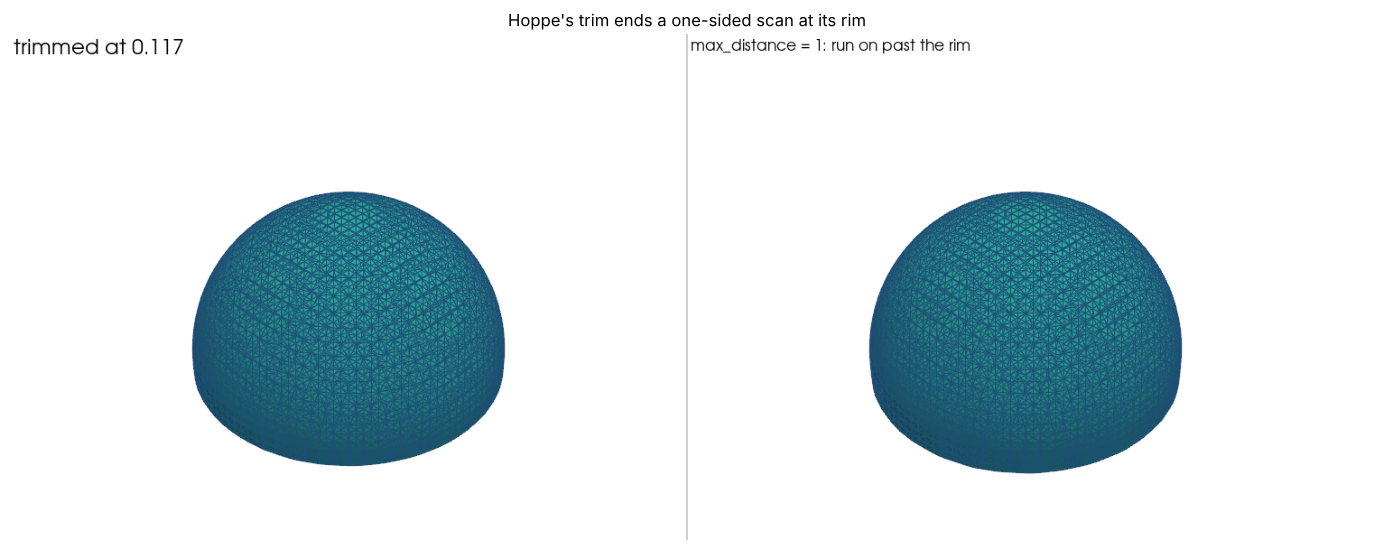

In [4]:
half = pts[pts[:, 2] > 0]
trimmed, r1 = mp.reconstruct_surface(half, normals=half, return_report=True)
loose, r2 = mp.reconstruct_surface(half, normals=half, max_distance=1.0, return_report=True)
for name, s, r in (('trimmed', trimmed, r1), ('max_distance=1', loose, r2)):
    tri = s.cells[0].data
    e = np.sort(np.concatenate([tri[:, [0, 1]], tri[:, [1, 2]], tri[:, [2, 0]]]), 1)
    _, c = np.unique(e, axis=0, return_counts=True)
    print(f'{name:15s} lowest z {s.points[:, 2].min():+.3f}, open edges {(c == 1).sum()}, '
          f'undefined nodes {r["num_undefined"]}')
render([(trimmed, f'trimmed at {r1["max_distance"]:.3f}', None),
        (loose, 'max_distance = 1: run on past the rim', None)],
       'Hoppe\'s trim ends a one-sided scan at its rim')

## From a scan file, in a pipeline, and on the command line

A PLY scan's `nx`, `ny` and `nz` properties are taken as its normals, so it reconstructs straight from the file; the pipeline step is `ReconstructSurface`, the verb `reconstruct` in both CLIs.

In [5]:
path = os.path.join(tempfile.mkdtemp(), 'scan.ply')
normals = mp.estimate_normals(cloud).point_data['normals']
# A PLY scan carries its normals as the vertex properties nx, ny, nz.
mp.write(path, mp.Mesh(cloud, [], point_data={c: normals[:, i].copy() for i, c in enumerate(('nx', 'ny', 'nz'))}))
scan = mp.read(path)
print('read', len(scan.points), 'points with', sorted(scan.point_data))
out, rep = mp.apply_operations(scan, [{'Op': 'ReconstructSurface', 'K': 8}])
print(rep['steps'][0])
print('meshioplusplus reconstruct scan.ply surface.stl --json')

read 8000 points with ['nx', 'ny', 'nz']
{'op': 'ReconstructSurface', 'NumSamples': 8000.0, 'Spacing': 0.046884755952095396, 'CellSize': 0.046884755952095396, 'MaxDistance': 0.09376951190419079, 'NumLatticePoints': 58078.0, 'NumUndefined': 5.0, 'NumTriangles': 62796.0, 'NumComponents': 1.0, 'EstimatedNormals': 0.0}
meshioplusplus reconstruct scan.ply surface.stl --json
